<h1 align='center' style='color:purple'>Clustering With K Means - Python Tutorial</h1>

## 3. The K-Means algorithm and its objective function

### 3.1 Steps

1. **Choose K** – the number of clusters.
2. **Initialise** K centroids $\mu_1, \dots, \mu_K$ (randomly picked points, or the smarter *k-means++* in scikit-learn).
3. **Assignment step** – give each point $x_i$ to the closest centroid using **Euclidean distance**:
$$d(x, \mu) = \sqrt{(x_1-\mu_1)^2 + (x_2-\mu_2)^2 + \dots}$$
$$c_i = \arg\min_{k}\; d(x_i, \mu_k)$$
4. **Update step** – move every centroid to the **mean** of the points assigned to it:
$$\mu_k = \frac{1}{|C_k|}\sum_{x_i \in C_k} x_i$$
5. **Repeat** steps 3–4 until the assignments (or centroids) stop changing — this is **convergence**.

### 3.2 What K-Means is minimising

K-Means minimises the **Within-Cluster Sum of Squares (WCSS)**, which scikit-learn calls **`inertia_`**:

$$\text{WCSS} = \sum_{k=1}^{K}\;\sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$

* Each assignment step and each update step can only **decrease (or keep)** the WCSS ⇒ the algorithm is guaranteed to converge.
* But it converges to a **local** minimum, which depends on the starting centroids. That is why scikit-learn runs it several times (`n_init`) and keeps the best result.

## 4. Numerical worked example (by hand) ✍️

Let's cluster **7 points** into **K = 2** clusters completely by hand, and then let Python confirm every number.

| Point | x | y |
|---|---|---|
| A | 1.0 | 1.0 |
| B | 1.5 | 2.0 |
| C | 3.0 | 4.0 |
| D | 5.0 | 7.0 |
| E | 3.5 | 5.0 |
| F | 4.5 | 5.0 |
| G | 3.5 | 4.5 |

**Initial centroids** (chosen as two far-apart points): $\mu_1 = A = (1, 1)$ and $\mu_2 = D = (5, 7)$.

---

### 🔁 Iteration 1

**Assignment step.** Example calculation for point **B (1.5, 2)**:

$$d(B,\mu_1) = \sqrt{(1.5-1)^2 + (2-1)^2} = \sqrt{0.25+1} = \sqrt{1.25} = 1.118$$
$$d(B,\mu_2) = \sqrt{(1.5-5)^2 + (2-7)^2} = \sqrt{12.25+25} = \sqrt{37.25} = 6.103$$

$1.118 < 6.103$ ⇒ **B → Cluster 1**. Doing this for every point:

| Point | d to μ₁ (1, 1) | d to μ₂ (5, 7) | Assigned to |
|---|---|---|---|
| A | 0.000 | 7.211 | **C1** |
| B | 1.118 | 6.103 | **C1** |
| C | 3.606 | 3.606 | **C1** *(tie → first centroid)* |
| D | 7.211 | 0.000 | **C2** |
| E | 4.717 | 2.500 | **C2** |
| F | 5.315 | 2.062 | **C2** |
| G | 4.301 | 2.915 | **C2** |

> ⚠️ Point **C** is *exactly* the same distance from both centroids. By convention (and in NumPy's `argmin`) ties go to the **first** centroid.

**Update step.**

$$\mu_1 = \text{mean}(A,B,C) = \left(\tfrac{1+1.5+3}{3},\; \tfrac{1+2+4}{3}\right) = (1.833,\; 2.333)$$
$$\mu_2 = \text{mean}(D,E,F,G) = \left(\tfrac{5+3.5+4.5+3.5}{4},\; \tfrac{7+5+5+4.5}{4}\right) = (4.125,\; 5.375)$$

---

### 🔁 Iteration 2

| Point | d to μ₁ (1.833, 2.333) | d to μ₂ (4.125, 5.375) | Assigned to |
|---|---|---|---|
| A | 1.572 | 5.376 | C1 |
| B | 0.471 | 4.276 | C1 |
| C | 2.034 | **1.777** | **C2** ⬅ *changed!* |
| D | 5.640 | 1.846 | C2 |
| E | 3.145 | 0.729 | C2 |
| F | 3.771 | 0.530 | C2 |
| G | 2.734 | 1.075 | C2 |

Point **C** has moved to Cluster 2. **Update step:**

$$\mu_1 = \text{mean}(A,B) = (1.25,\; 1.5)$$
$$\mu_2 = \text{mean}(C,D,E,F,G) = \left(\tfrac{3+5+3.5+4.5+3.5}{5},\; \tfrac{4+7+5+5+4.5}{5}\right) = (3.9,\; 5.1)$$

---

### 🔁 Iteration 3

| Point | d to μ₁ (1.25, 1.5) | d to μ₂ (3.9, 5.1) | Assigned to |
|---|---|---|---|
| A | 0.559 | 5.022 | C1 |
| B | 0.559 | 3.920 | C1 |
| C | 3.052 | 1.421 | C2 |
| D | 6.657 | 2.195 | C2 |
| E | 4.161 | 0.412 | C2 |
| F | 4.776 | 0.608 | C2 |
| G | 3.750 | 0.721 | C2 |

No point changed cluster ⇒ the centroids stay at $(1.25, 1.5)$ and $(3.9, 5.1)$ ⇒ **converged ✅**

**Final clusters:** C1 = {A, B}, C2 = {C, D, E, F, G}

### 📉 WCSS at the end

$$\text{WCSS} = \underbrace{(0.25^2+0.5^2) + (0.25^2+0.5^2)}_{\text{C1: } A, B = 0.625} + \underbrace{(0.9^2+1.1^2) + (1.1^2+1.9^2) + (0.4^2+0.1^2) + (0.6^2+0.1^2) + (0.4^2+0.6^2)}_{\text{C2} = 7.9} = 8.525$$

WCSS went **33.25 → 11.23 → 8.525** across the iterations (computed with the centroids used in each assignment step) — it never increases.

Now let's check all of this with code 👇

## 5. Evaluation metrics for clustering 📏

Because clustering has **no ground-truth labels**, we can't use accuracy. Instead we use:

* **Internal metrics** – judge the clusters using only the data (compactness & separation).
* **External metrics** – compare to true labels, *only if* they happen to be available (e.g. for teaching datasets like Iris).

### 5.1 Internal metrics

| Metric | Formula / idea | Range | Better when | In sklearn |
|---|---|---|---|---|
| **WCSS / Inertia** | $\sum_k \sum_{x \in C_k}\lVert x-\mu_k\rVert^2$ — compactness | $[0, \infty)$ | **Lower** (but *always* falls as K grows) | `km.inertia_` |
| **Silhouette score** | $s(i) = \dfrac{b(i) - a(i)}{\max\{a(i), b(i)\}}$ averaged over all points | $[-1, 1]$ | **Higher** (≈1 great, ≈0 overlapping, <0 wrong cluster) | `silhouette_score` |


In the silhouette:
* $a(i)$ = average distance from point $i$ to the **other points in its own cluster** (how tight its cluster is),
* $b(i)$ = average distance from point $i$ to the points of the **nearest other cluster** (how far the neighbours are).

### 5.2 External metrics (need true labels)

| Metric | Range | Meaning |
|---|---|---|
| **Adjusted Rand Index (ARI)** | $[-1, 1]$ | 1 = perfect match with true labels, ≈0 = random labelling |
| **Normalized Mutual Information (NMI)** | $[0, 1]$ | 1 = clusters carry exactly the same information as the labels |

Both ignore the *names* of the clusters — cluster "0" vs "1" swapped still scores 1.0.

---

### ✍️ Hand calculation: silhouette of point A in the worked example

Final clusters: C1 = {A, B}, C2 = {C, D, E, F, G}.

**a(A)** – A's own cluster contains only B:
$$a(A) = d(A,B) = 1.118$$

**b(A)** – average distance from A to every point of C2:
$$b(A) = \frac{d(A,C)+d(A,D)+d(A,E)+d(A,F)+d(A,G)}{5} = \frac{3.606+7.211+4.717+5.315+4.301}{5} = \frac{25.150}{5} = 5.030$$

$$s(A) = \frac{5.030 - 1.118}{\max(1.118,\; 5.030)} = \frac{3.912}{5.030} = \mathbf{0.778}$$

A is **well inside** its cluster (close to 1). Let's verify, and compute all metrics for the worked example:

In [21]:
from sklearn.cluster import KMeans
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from matplotlib import pyplot as plt
from sklearn.metrics import silhouette_score
import numpy as np
%matplotlib inline

# Load the data set

In [22]:
df = pd.read_csv("income - income.csv")
df.sample(10)

,Name,Age,Income($)
21,Abdul,39,58000
13,Jared,28,51000
8,Brad,36,156000
5,Gautam,39,155000
4,Kory,42,150000
14,Stark,29,49500
19,Alia,39,80000
7,Andrea,38,162000
3,Ismail,28,60000
6,David,41,160000


# Plot the scater plot

Text(0, 0.5, 'Income($)')

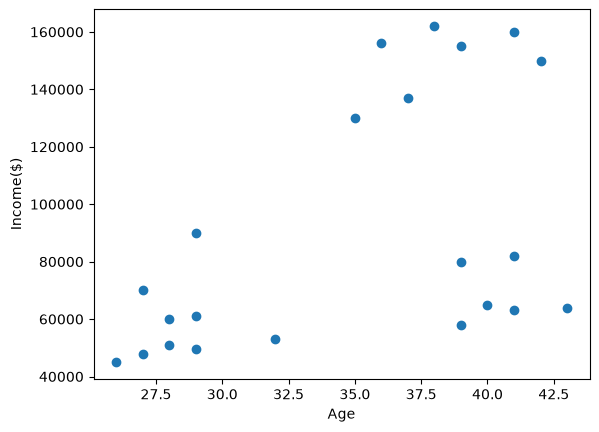

In [23]:
plt.scatter(df.Age, df["Income($)"])
plt.xlabel('Age')
plt.ylabel('Income($)')


By eye there are clearly **3 groups**: young/low income (bottom-left), older/high income (top-right) and older/medium income (bottom-right).

# Bulid and Train the model

In [24]:
Km = KMeans(n_clusters =3)
y_predicted = Km.fit_predict(df[['Age' , "Income($)"]])
y_predicted

array([1, 1, 1, 1, 2, 2, 2, 2, 2, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
      dtype=int32)

# Assgin the cluster table to the samples 

In [25]:
df["cluster"] = y_predicted
df.sample(10)

,Name,Age,Income($),cluster
17,Priyanka,41,63000,1
19,Alia,39,80000,1
20,Sid,41,82000,1
16,Dipika,40,65000,1
4,Kory,42,150000,2
10,Donald,37,137000,0
9,Angelina,35,130000,0
8,Brad,36,156000,2
5,Gautam,39,155000,2
12,Arnold,27,48000,1


In [26]:
Km.cluster_centers_

array([[3.60000000e+01, 1.33500000e+05],
       [3.32000000e+01, 6.26333333e+04],
       [3.92000000e+01, 1.56600000e+05]])

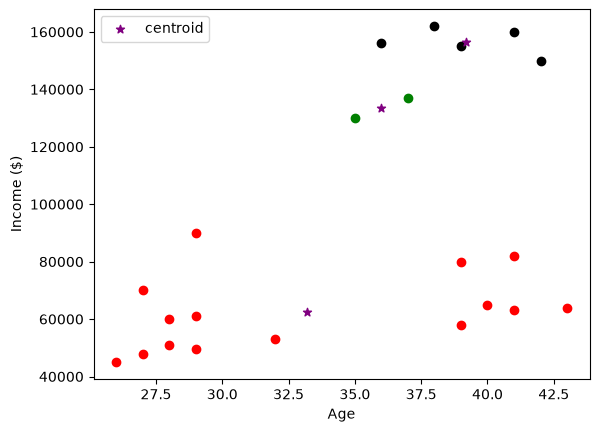

In [27]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(Km.cluster_centers_[:,0],Km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.xlabel('Age')
plt.ylabel('Income ($)')
plt.legend()

The clusters are cut **horizontally by income only** — some young people end up with older people. Why?

<h4 style='color:purple'>Preprocessing using min max scaler</h4>


**Min–Max scaling** squeezes every feature into the range $[0, 1]$:

$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

**Worked example** for Rob (Age 27, Income 70,000). Age range is 26 → 43, Income range is 45,000 → 162,000:

In [28]:
scaler = MinMaxScaler()

df[['Income($)', 'Age']] = scaler.fit_transform(
    df[['Income($)', 'Age']]
)

In [29]:
df.sample(10)

,Name,Age,Income($),cluster
2,Mohan,0.176471,0.136752,1
0,Rob,0.058824,0.213675,1
5,Gautam,0.764706,0.940171,2
18,Nick,1.000000,0.162393,1
12,Arnold,0.058824,0.025641,1
20,Sid,0.882353,0.316239,1
10,Donald,0.647059,0.786325,0
19,Alia,0.764706,0.299145,1
4,Kory,0.941176,0.897436,2
16,Dipika,0.823529,0.170940,1


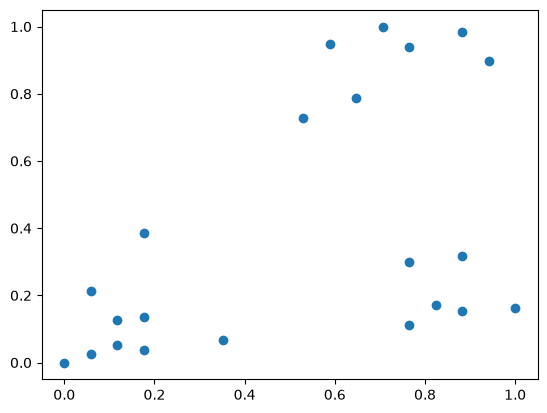

In [30]:
plt.scatter(df.Age,df['Income($)'])

In [31]:
km = KMeans(n_clusters=3)
y_predicted = km.fit_predict(df[['Age','Income($)']])
y_predicted

array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2],
      dtype=int32)

In [32]:
df['cluster']=y_predicted
df.sample(10)

,Name,Age,Income($),cluster
14,Stark,0.176471,0.038462,1
21,Abdul,0.764706,0.111111,2
5,Gautam,0.764706,0.940171,0
1,Michael,0.176471,0.384615,1
17,Priyanka,0.882353,0.153846,2
13,Jared,0.117647,0.051282,1
12,Arnold,0.058824,0.025641,1
3,Ismail,0.117647,0.128205,1
8,Brad,0.588235,0.948718,0
6,David,0.882353,0.982906,0


In [33]:
km.cluster_centers_

array([[0.72268908, 0.8974359 ],
       [0.1372549 , 0.11633428],
       [0.85294118, 0.2022792 ]])

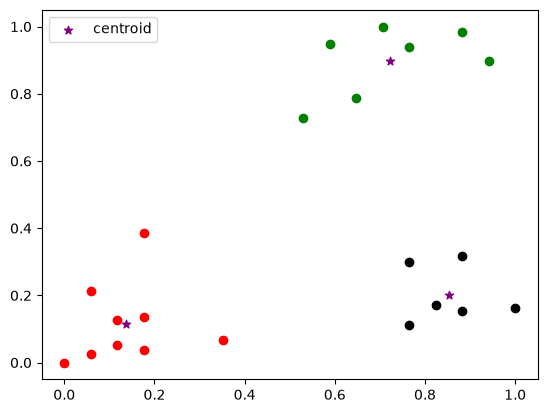

In [34]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.legend()

<h4 style='color:purple'>Elbow Plot</h4>

[![Picture1.png](https://i.postimg.cc/k5xhZXvY/Picture1.png)](https://postimg.cc/3yxB0h62)

# SSE and silhouette scores



---



In [35]:
x = df[['Age','Income($)']]
k_range = range(2,10)

sse,silhouette_scores = [],[]

for k in k_range:
    km = KMeans(n_clusters=k , random_state=42 , n_init=10).fit(x)
    sse.append(km.inertia_)
    silhouette_scores.append(__import__('sklearn.metrics', fromlist=['silhouette_score']).silhouette_score(x, km.labels_))


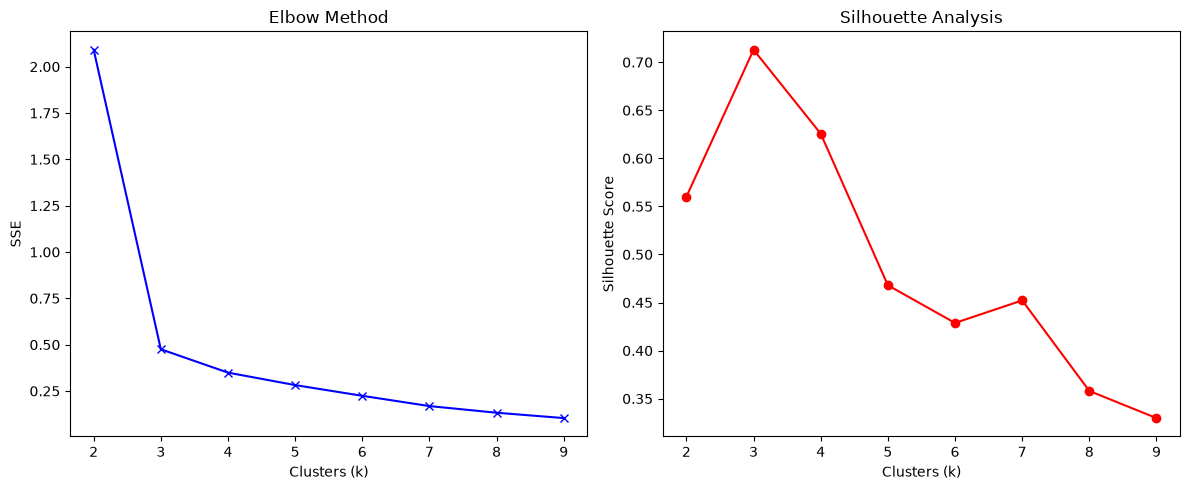

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(k_range, sse, 'bx-')
ax[0].set(title='Elbow Method', xlabel='Clusters (k)', ylabel='SSE')

ax[1].plot(k_range, silhouette_scores, 'ro-')
ax[1].set(title='Silhouette Analysis', xlabel='Clusters (k)', ylabel='Silhouette Score')

plt.tight_layout()
plt.show()

# load the dataset

In [37]:
df = pd.read_csv("income - income.csv")

print(df.head())

X = df[['Age', 'Income($)']].to_numpy(dtype=float)

      Name  Age  Income($)
0      Rob   27      70000
1  Michael   29      90000
2    Mohan   29      61000
3   Ismail   28      60000
4     Kory   42     150000


# Z-score normalization

In [38]:
# Z-score normalization
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

print("Standardized Data:\n", X_scaled[:5])

Standardized Data:
 [[-1.35605536 -0.48068427]
 [-1.00915747 -0.01015907]
 [-1.00915747 -0.69242061]
 [-1.18260641 -0.71594687]
 [ 1.24567876  1.40141653]]


# Define the custom K-Means algorithm

In [39]:
def kmeans(x , k , max_iters=100):
    # Randomly initialize centroids
    np.random.seed(42)
    centroids = x[np.random.choice(len(x), k, replace=False)].copy()

    for _ in range(max_iters):
        # Assign clusters based on closest centroid
        labels = np.argmin(np.array([np.sum((x-c)**2, axis=1) for c in centroids]).T, axis=1)

        # Update centroids
        new_centroids = np.array([x[labels == i].mean(axis=0) if np.any(labels == i) else centroids[i] for i in range(k)])

        # Check for convergence
        if np.all(centroids == new_centroids):
            break

        centroids = new_centroids

    return centroids , labels

In [40]:
k = 3
centroids, labels = kmeans(X_scaled, k)

df['Cluster'] = labels

print(df.head())
print("Centroids:\n", centroids)

      Name  Age  Income($)  Cluster
0      Rob   27      70000        0
1  Michael   29      90000        0
2    Mohan   29      61000        0
3   Ismail   28      60000        0
4     Kory   42     150000        2
Centroids:
 [[-1.1247901  -0.74862223]
 [ 0.98550535 -0.51205261]
 [ 0.60143983  1.40141653]]


<h4 style='color:purple'>Exercise</h4>

## 📝 Lab Assignment: K-Means Clustering on the Wine Dataset — From Scratch vs. scikit-learn

### 🎯 Objective
Apply K-Means clustering to the **Wine dataset** in two ways:
1. a **from-scratch implementation**, written by you using only NumPy;
2. the **predefined `KMeans`** class from scikit-learn.

Evaluate both with standard clustering metrics and compare the results.

---

### 📂 Step 1 — Load the dataset
```python
from sklearn.datasets import load_wine
wine = load_wine()
X, y_true = wine.data, wine.target      # 178 wines, 13 chemical features, 3 cultivars
```
> ⚠️ **Do NOT use `y_true` for clustering.** Keep it aside and use it **only** for the external metrics (ARI, NMI) in Step 6.

---

### 🔍 Step 2 — Explore and preprocess
- Put `X` into a DataFrame with `wine.feature_names`. Show its shape, `head()` and `describe()`.
- Look at the feature ranges: for example, *proline* goes up to ~1680, while *hue* is around 1.
- Apply `StandardScaler`. **Explain in a markdown cell why scaling is necessary** for K-Means here.
- Use **PCA** to get 2 components (`PCA(n_components=2)`), **for plotting only**. Cluster on all 13 scaled features.

---

### 🛠️ Step 3 — K-Means from scratch
Write a function `kmeans_scratch(X, k, max_iters=100, n_init=10, seed=42)` using **only NumPy**. It must:
1. **Initialise** K centroids by picking random data points.
2. **Assign** each point to its nearest centroid using Euclidean distance.
3. **Update** each centroid to the mean of the points assigned to it.
4. **Stop** when the centroids no longer move (or `max_iters` is reached).
5. Repeat the whole run `n_init` times and keep the run with the **lowest WCSS**.
6. **Return** `centroids`, `labels`, `wcss` and the number of iterations.

Also write your own function to compute **WCSS**:
$$\text{WCSS} = \sum_{k=1}^{K}\sum_{x_i \in C_k}\lVert x_i-\mu_k\rVert^2$$

⭐ **Bonus:** implement the **silhouette score from scratch** and check that it matches `sklearn.metrics.silhouette_score`.

---

### 📦 Step 4 — K-Means with scikit-learn
```python
from sklearn.cluster import KMeans
km = KMeans(n_clusters=k, n_init=10, random_state=42)
labels_sk = km.fit_predict(X_scaled)
```
Report `km.cluster_centers_`, `km.inertia_` and `km.n_iter_`.

---

### 📈 Step 5 — Choose the optimal K
For **K = 2 to 10**, using **both** implementations:
- Plot the **Elbow curve** (WCSS vs K).
- Plot the **Silhouette score vs K**.
- State your chosen K and explain why. Does it match the 3 true cultivars?

---

### 📏 Step 6 — Evaluate both models
Fill in this table for your chosen K:

| Metric | Type | Better | Scratch | scikit-learn |
|---|---|---|---|---|
| WCSS / Inertia | Internal | ↓ Lower | | |
| Silhouette score | Internal | ↑ Higher (max 1) | | |

In [41]:
from sklearn.datasets import load_wine
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

wine = load_wine()
X, y_true = wine.data, wine.target
print(X.shape, y_true.shape)

(178, 13) (178,)


In [42]:
df_wine = pd.DataFrame(X, columns=wine.feature_names)
print(df_wine.shape)
display(df_wine.head())
display(df_wine.describe())

(178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [43]:
ranges = pd.DataFrame({
    'min': df_wine.min(),
    'max': df_wine.max(),
    'range': df_wine.max() - df_wine.min()
})
display(ranges)

,min,max,range
alcohol,11.03,14.83,3.80
malic_acid,0.74,5.80,5.06
ash,1.36,3.23,1.87
alcalinity_of_ash,10.60,30.00,19.40
magnesium,70.00,162.00,92.00
total_phenols,0.98,3.88,2.90
flavanoids,0.34,5.08,4.74
nonflavanoid_phenols,0.13,0.66,0.53
proanthocyanins,0.41,3.58,3.17
color_intensity,1.28,13.00,11.72


In [44]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
df_scaled = pd.DataFrame(X_scaled, columns=wine.feature_names)
display(df_scaled.head())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


In [45]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(X_pca.shape)
print(pca.explained_variance_ratio_)

(178, 2)
[0.36198848 0.1920749 ]


In [46]:
def compute_wcss(X, centroids, labels):
    wcss = 0.0
    for k in range(len(centroids)):
        cluster_points = X[labels == k]
        if len(cluster_points) > 0:
            wcss += np.sum((cluster_points - centroids[k]) ** 2)
    return wcss

In [47]:
def kmeans_scratch(X, k, max_iters=100, n_init=10, seed=42):
    best_centroids = None
    best_labels = None
    best_wcss = np.inf
    best_iters = 0

    for init in range(n_init):
        rng = np.random.default_rng(seed + init if seed is not None else None)
        indices = rng.choice(len(X), size=k, replace=False)
        centroids = X[indices].copy()

        for it in range(1, max_iters + 1):
            distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
            labels = np.argmin(distances, axis=1)

            new_centroids = np.zeros_like(centroids)
            for j in range(k):
                mask = (labels == j)
                if np.any(mask):
                    new_centroids[j] = X[mask].mean(axis=0)
                else:
                    new_centroids[j] = X[rng.choice(len(X))]

            if np.allclose(centroids, new_centroids):
                break
            centroids = new_centroids

        wcss = compute_wcss(X, centroids, labels)
        if wcss < best_wcss:
            best_wcss = wcss
            best_centroids = centroids
            best_labels = labels
            best_iters = it

    return best_centroids, best_labels, best_wcss, best_iters

In [48]:
centroids_scratch, labels_scratch, wcss_scratch, iters_scratch = kmeans_scratch(X_scaled, k=3, n_init=10, seed=42)
print("Scratch WCSS:", wcss_scratch)
print("Scratch Iterations:", iters_scratch)
print("Scratch Centroids Shape:", centroids_scratch.shape)

Scratch WCSS: 1277.9284888446423
Scratch Iterations: 3
Scratch Centroids Shape: (3, 13)


In [49]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_sk = km.fit_predict(X_scaled)
print("scikit-learn Inertia:", km.inertia_)
print("scikit-learn Iterations:", km.n_iter_)
print("scikit-learn Centers Shape:", km.cluster_centers_.shape)

scikit-learn Inertia: 1277.928488844642
scikit-learn Iterations: 7
scikit-learn Centers Shape: (3, 13)


In [50]:
from sklearn.metrics import silhouette_score

k_values = list(range(2, 11))
wcss_scratch_list = []
wcss_sk_list = []
sil_scratch_list = []
sil_sk_list = []

for k in k_values:
    c_sc, l_sc, w_sc, _ = kmeans_scratch(X_scaled, k=k, n_init=10, seed=42)
    wcss_scratch_list.append(w_sc)
    sil_scratch_list.append(silhouette_score(X_scaled, l_sc))

    km_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    wcss_sk_list.append(km_k.inertia_)
    sil_sk_list.append(silhouette_score(X_scaled, km_k.labels_))

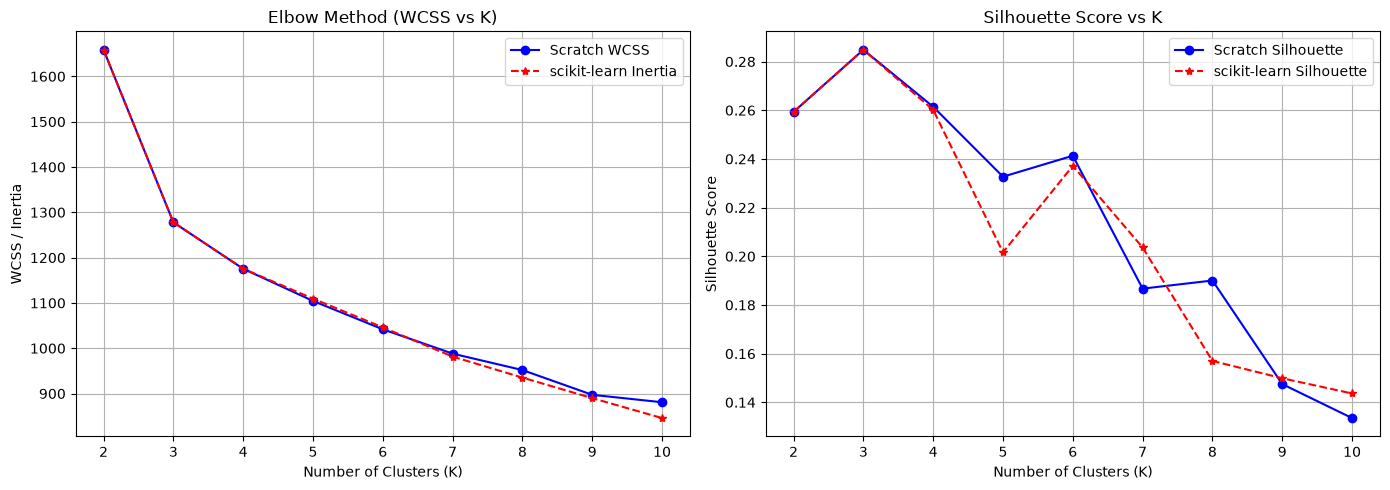

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, wcss_scratch_list, 'bo-', label='Scratch WCSS')
axes[0].plot(k_values, wcss_sk_list, 'r*--', label='scikit-learn Inertia')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('WCSS / Inertia')
axes[0].set_title('Elbow Method (WCSS vs K)')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(k_values, sil_scratch_list, 'bo-', label='Scratch Silhouette')
axes[1].plot(k_values, sil_sk_list, 'r*--', label='scikit-learn Silhouette')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score vs K')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [52]:
print("Optimal K: 3")
print(f"WCSS at K=3: Scratch = {wcss_scratch_list[1]:.2f}, scikit-learn = {wcss_sk_list[1]:.2f}")
print(f"Silhouette Score at K=3: Scratch = {sil_scratch_list[1]:.4f}, scikit-learn = {sil_sk_list[1]:.4f}")

Optimal K: 3
WCSS at K=3: Scratch = 1277.93, scikit-learn = 1277.93
Silhouette Score at K=3: Scratch = 0.2849, scikit-learn = 0.2849


In [53]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

eval_df = pd.DataFrame({
    'Metric': [
        'WCSS / Inertia',
        'Silhouette Score',
        'Adjusted Rand Index (ARI)',
        'Normalized Mutual Info (NMI)',
        'Iterations to Converge'
    ],
    'Type': ['Internal', 'Internal', 'External', 'External', 'Performance'],
    'Better': ['Lower', 'Higher', 'Higher', 'Higher', 'Lower'],
    'Scratch': [
        round(wcss_scratch, 2),
        round(silhouette_score(X_scaled, labels_scratch), 4),
        round(adjusted_rand_score(y_true, labels_scratch), 4),
        round(normalized_mutual_info_score(y_true, labels_scratch), 4),
        iters_scratch
    ],
    'scikit-learn': [
        round(km.inertia_, 2),
        round(silhouette_score(X_scaled, labels_sk), 4),
        round(adjusted_rand_score(y_true, labels_sk), 4),
        round(normalized_mutual_info_score(y_true, labels_sk), 4),
        km.n_iter_
    ]
})
display(eval_df)

,Metric,Type,Better,Scratch,scikit-learn
0,WCSS / Inertia,Internal,Lower,1277.9300,1277.9300
1,Silhouette Score,Internal,Higher,0.2849,0.2849
2,Adjusted Rand Index (ARI),External,Higher,0.8975,0.8975
3,Normalized Mutual Info (NMI),External,Higher,0.8759,0.8759
4,Iterations to Converge,Performance,Lower,3.0000,7.0000


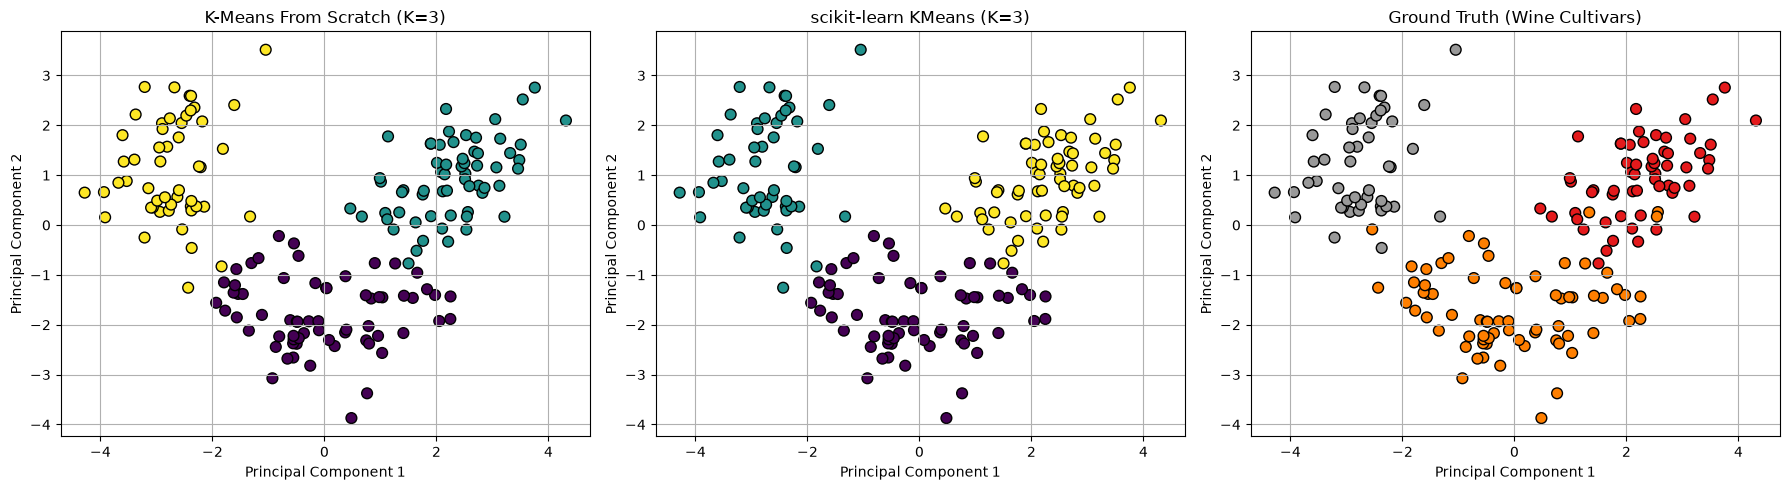

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_scratch, cmap='viridis', edgecolors='k', s=60)
axes[0].set_title('K-Means From Scratch (K=3)')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].grid(True)

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_sk, cmap='viridis', edgecolors='k', s=60)
axes[1].set_title('scikit-learn KMeans (K=3)')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
axes[1].grid(True)

axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap='Set1', edgecolors='k', s=60)
axes[2].set_title('Ground Truth (Wine Cultivars)')
axes[2].set_xlabel('Principal Component 1')
axes[2].set_ylabel('Principal Component 2')
axes[2].grid(True)

plt.tight_layout()
plt.show()